In [1]:
import glob
from matplotlib.pylab import seed
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')



def bootstrap_group(sub_df, diag_cols, phase_col, n_boot=1000,
                     sample_size=10):
    """
    Bootstrap a single model's slice of the DataFrame.
 
    Parameters
    ----------
    sub_df : pd.DataFrame
        Rows = realisations of one model. Must contain `phase_col` and
        `diag_cols`.
    diag_cols : list of str
        The scalar diagnostic column names to bootstrap simultaneously.
    phase_col : str
        Column with NAO phase flags (e.g. -1, 0, 1).
    n_boot : int
        Number of bootstrap replicates.
    sample_size : int
        Number of realisations drawn (with replacement) per replicate.
    rng : np.random.Generator, optional
 
    Returns
    -------
    dict: "overall" plus one key per NAO phase value present in `phase_col`
          -> pd.DataFrame, shape (n_boot, len(diag_cols)), columns = diag_cols
    """
    rng = np.random.default_rng(seed=100) 
    diag_values = sub_df[diag_cols].to_numpy()  
    phase_flags = sub_df[phase_col].to_numpy()
    phases = np.unique(phase_flags)
    phase_idx = {p: np.where(phase_flags == p)[0] for p in phases}
 
    out = {} 
    for p in phases:
        out[p] = np.full((n_boot, len(diag_cols)), np.nan)
 
    for i in range(n_boot):
        for p in phases:
            idx = phase_idx[p]
            if len(idx) == 0:
                continue  # if no realizatinos in this phase, stays NaN
            draw_p = rng.choice(idx, size=sample_size, replace=True)
            out[p][i] = diag_values[draw_p].mean(axis=0)
 
    return {k: pd.DataFrame(v, columns=diag_cols) for k, v in out.items()}
 
 
def bootstrap_all_models(df, diag_cols, model_level, phase_col,
                          n_boot=1000, sample_size=10):
    """
    Run bootstrap_group for every model found at `model_level` of df's index.
 
    Returns
    -------
    dict: model_name -> (dict returned by bootstrap_group)
    """
    results = {}
    for model_name, sub_df in df.groupby(level=model_level):
        out = bootstrap_group(
            sub_df, diag_cols, phase_col,
            n_boot=n_boot, sample_size=sample_size
        )
        results[model_name] = pd.concat(out).reset_index().rename(columns={'level_0': 'flag_nao'}).drop(['level_1'], axis=1)
    return results


def control_values(data):
    # account for rounding errors
    df_tmp = []
    for nao, phase in zip([-1,0,1], ['NAO-', 'NAO0', 'NAO+']):
        tmp = data.loc[nao]
        index = tmp.drop('count', axis=1).sum(axis=1)
        tmp.loc[index == 99, phase] = tmp.loc[index == 99][phase] + 1
        tmp.loc[index == 101, phase] = tmp.loc[index == 101][phase] - 1
        tmp = tmp.reset_index()
        tmp['flag_pi'] = nao
        df_tmp.append(tmp)
   
    return  pd.concat(df_tmp).set_index(['flag_pi', 'model'])

In [ ]:
plotdir = "/home/kperny/VolMIP_stratosphere/plots/PAPER/"
piControl = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv")
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_flags.csv")
models = df_flags['model'].unique()

df_flags = df_flags.set_index(['model', 'realization']).drop('year', axis=1)
df_flags['count'] = 1

In [ ]:
# # get amount of realizations of each NAO state in piControl
# df_out = df_flags.groupby(['model', 'flag_pi']).sum()
# df_out = df_out.reset_index().set_index('flag_pi')
# df_out = df_out.drop(['nao_pi', 'nao_volc', 'flag_volc'], axis=1)
# df_rel_new = df_out.copy()

# # create index based on NAO state for piControl
# naon = df_flags.where(df_flags['flag_pi'] == -1).dropna().index
# naop = df_flags.where(df_flags['flag_pi'] == 1).dropna().index
# nao0 = df_flags.where(df_flags['flag_pi'] == 0).dropna().index


# # iterate over NAO state and count state changes in volc
# states = ['NAO-', 'NAO0', 'NAO+']
# for idx, value in zip([naon, naop, nao0], [-1, 1, 0]):
#     volc = df_flags.loc[idx].drop(columns=['nao_pi', 'nao_volc', 'flag_pi'])
#     df_out.loc[value, states] = volc.groupby(['model', 'flag_volc']).sum().unstack().values
#     df_rel_new.loc[value, states] = volc.groupby(['model', 'flag_volc']).sum().unstack().values / df_out.reset_index().set_index(['flag_pi', 'model']).loc[value]['count'].values.reshape(6,1)

# df_nao = df_out.reset_index().set_index(['flag_pi', 'model']).sort_index()
# df_nao = df_nao.fillna(0)

# df_rel = df_rel_new.reset_index().set_index(['flag_pi', 'model']).sort_index()
# df_rel = df_rel.fillna(0)

# # calculate percantage and round to integer
# df_pro = df_rel.copy()
# df_pro[states] = df_pro[states] *100

In [ ]:
df = df_flags.reset_index().set_index(['flag_pi','model']).sort_index()

df_out = []
for model in models:
    model_list = []
    for nao in [-1, 0, 1]:
        percent = []
        for i in range(100):
            tmp = df.loc[nao,model].drop(columns=['nao_pi', 'nao_volc'])
            tmp['flag_volc'] = tmp['flag_volc'].replace({-1: 'NAO-', 0:'NAO0', 1: 'NAO+'})
            choice = np.random.choice(tmp['realization'].values, size=25)
            percent.append((tmp.set_index('realization').loc[choice].groupby('flag_volc').sum() / 25).T.rename_axis(None, axis=1).reset_index().drop(['index'], axis=1))
        tmp = pd.concat(percent)
        tmp['nao_flag'] = nao
        model_list.append(tmp)
    tmp = pd.concat(model_list)
    tmp['model'] = model
    df_out.append(tmp)
df_out = pd.concat(df_out)
df_out = df_out.set_index(['nao_flag', 'model']).sort_index()
df_out = df_out.fillna(0)

states = ['NAO-', 'NAO0', 'NAO+']
df_pro = df_out[states] * 100
df_pro['count'] = 25

df_std = df_pro.reset_index().groupby(['model', 'nao_flag']).std()
df_std = df_std.reset_index().set_index(['nao_flag', 'model']).sort_index()
df_pro = df_pro.reset_index().groupby(['model', 'nao_flag']).mean()
df_pro = df_pro.reset_index().set_index(['nao_flag', 'model']).sort_index()

[47 49 40  0 29 46] NAO+
[ -7 -19 -21 -50 -40 -32] NAO0
[-45 -24 -29 -12 -44 -21] NAO-
[27 47 43 51 43 45] NAO+
[-51 -13 -11 -37 -23 -29] NAO-
[16 52 12 27 25 29] NAO0


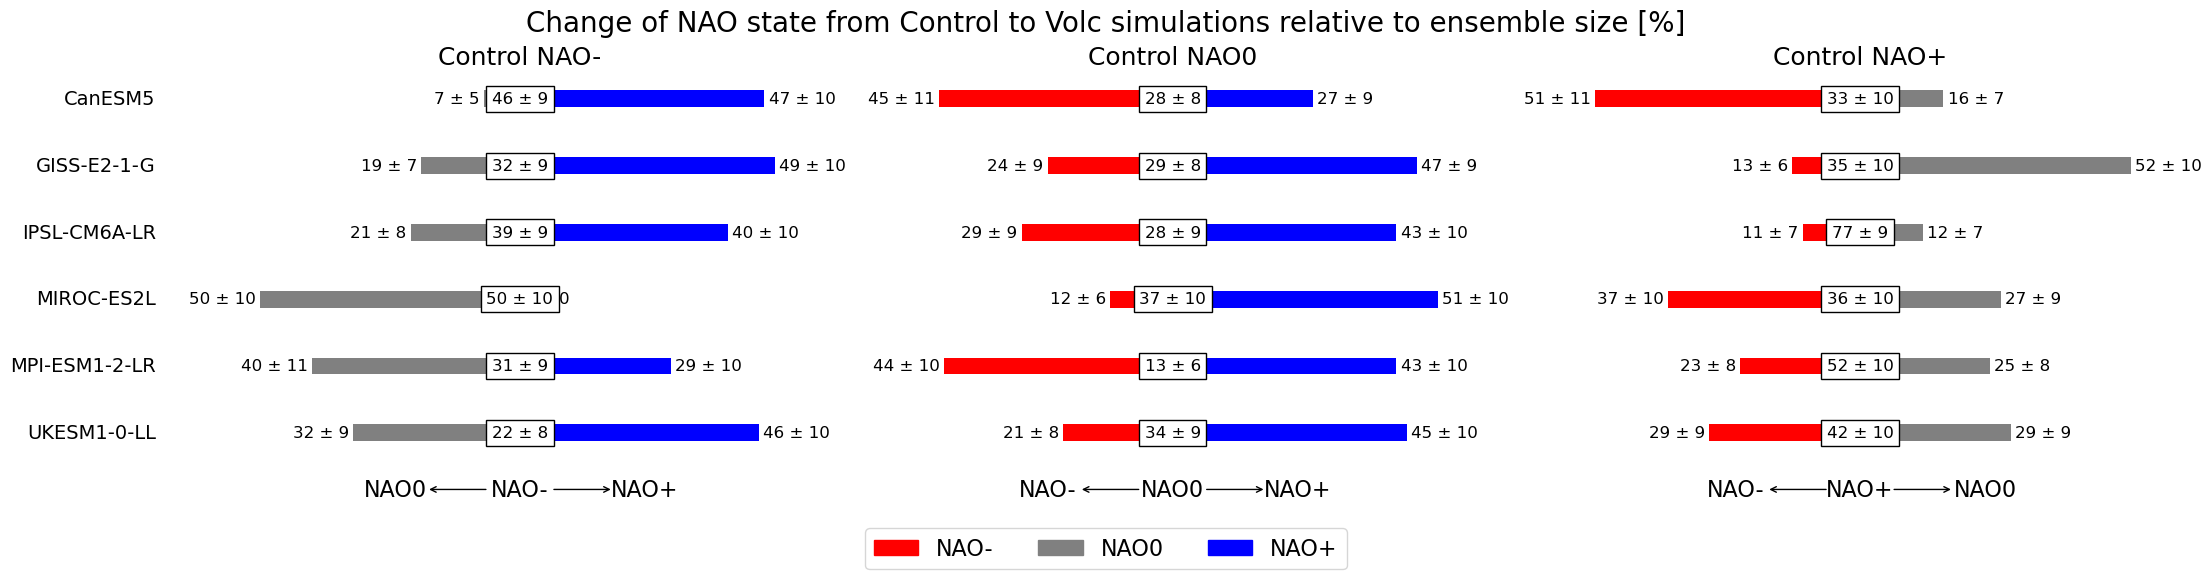

In [56]:
from matplotlib import container


df_pro = df_pro.round(0).apply(pd.to_numeric, downcast='integer')
df_std = df_std.round(0).apply(pd.to_numeric, downcast='integer')
df_pro_control = control_values(df_pro)

fig, axs = plt.subplots(1,3, figsize=(22, 5), sharey=True, layout='constrained')

data = df_pro_control.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAO+'], height=0.25, color = 'b')
axs[0].barh(data['model'], -data['NAO0'], height=0.25, color = 'grey')

data = df_pro_control.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAO-'], height=0.25, color = 'r')
axs[1].barh(data['model'], data['NAO+'], height=0.25, color = 'b')

data = df_pro_control.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAO-'], height=0.25, color = 'r')
axs[2].barh(data['model'], data['NAO0'], height=0.25, color = 'grey')


for ax, nao, state, color, naovs in zip(axs, [-1,0,1], ['NAO-', 'NAO0', 'NAO+'], ['red', 'grey', 'blue'], [['NAO+', 'NAO0'], ['NAO-', 'NAO+'], ['NAO-', 'NAO0']]):
    ax.set_xlim(-60, 60)
    for container, naov in zip(ax.containers, naovs):
        print(container.datavalues, naov)
        labels = [str(abs(value)) + ' ± ' + str(std) for value, std in zip(container.datavalues, df_std.loc[nao][naov].values)]
        ax.bar_label(container, labels=labels, label_type='edge', padding=3, fontsize=12)

    for model in models:
        ax.annotate(str(df_pro_control.loc[nao, model][state]) + ' ± ' + str(df_std.loc[nao, model][state]), xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    ax.set_xlabel(state, fontsize=16)
    ax.set_axis_off()
    ax.invert_yaxis()

    # ax.set_ylabel(data[model].values)
    ax.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
            arrowprops=dict(arrowstyle="->", color='k'))
    ax.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
            arrowprops=dict(arrowstyle="<-", color='k'))

# axs[0].tick_params(axis='both', labelsize=12)
    
axs[0].annotate('NAO0', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO-', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO+', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO0', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

for i, model in enumerate(models):
    axs[0].annotate(model, xy=(-70,i), xycoords='data', ha='right', va='center', fontsize=14, color='k', annotation_clip=False)

axs[0].set_title('Control NAO-', fontsize=18)
axs[1].set_title('Control NAO0', fontsize=18)
axs[2].set_title('Control NAO+', fontsize=18)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='red', label='NAO-')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='blue', label='NAO+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.15))

plt.suptitle('Change of NAO state from Control to Volc simulations relative to ensemble size [%]', fontsize=20)
plt.savefig('/home/kperny/VolMIP_stratosphere/plots/bootstrapping/supp_figure1a.png', dpi=200, bbox_inches='tight')

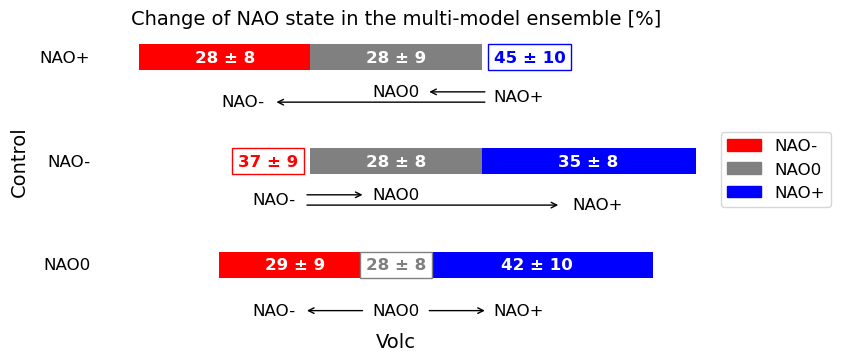

In [31]:
fig, axs = plt.subplots( 1,1, figsize=(7,3.5), layout='constrained')

data = df_pro.groupby(['nao_flag']).mean().round(0).apply(pd.to_numeric, downcast='integer')
data_std = df_std.groupby(['nao_flag']).mean().round(0).apply(pd.to_numeric, downcast='integer')

axs.barh('NAO0', -data.loc[0]['NAO-'], height=0.25, color = 'r')
axs.barh('NAO0', data.loc[0]['NAO+'], height=0.25, color = 'b')

axs.barh('NAO-', data.loc[-1]['NAO+'] + data.loc[-1]['NAO0'] / 2, height=0.25, color = 'b')
axs.barh('NAO-', -data.loc[-1]['NAO0']/ 2, height=0.25, color = 'grey')
axs.barh('NAO-', data.loc[-1]['NAO0'] / 2, height=0.25, color = 'grey')

axs.barh('NAO+', -data.loc[1]['NAO-'] - data.loc[1]['NAO0'] / 2, height=0.25, color = 'r')
axs.barh('NAO+', -data.loc[1]['NAO0']/ 2, height=0.25, color = 'grey')
axs.barh('NAO+', data.loc[1]['NAO0'] / 2, height=0.25, color = 'grey')


axs.set_xlim(-50, 50)
# Annnotate piControl NAO+
axs.annotate(str(data.loc[1]['NAO-']) + " ± " + str(data_std.loc[1]['NAO-']), xy=( - data.loc[1]['NAO0'] / 2 - data.loc[1]['NAO-'] / 2, 'NAO+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(str(data.loc[1]['NAO0']) + " ± " + str(data_std.loc[1]['NAO0']), xy=(0, 'NAO+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(str(data.loc[1]['NAO+']) + " ± " + str(data_std.loc[1]['NAO+']), xy=(data.loc[1]['NAO0'] / 2 + 2, 'NAO+'), xycoords='data', ha='left', va='center', 
             fontsize=12, weight='bold', color='b', bbox=dict(fc='white', ec='b'))

# Annotate piControl NAO-
axs.annotate(str(data.loc[-1]['NAO-']) + " ± " + str(data_std.loc[-1]['NAO-']), xy=(- data.loc[-1]['NAO0'] / 2 - 2, 'NAO-'), xycoords='data', ha='right', va='center', 
             fontsize=12, weight='bold', color='r', bbox=dict(fc='white', ec='r'))
axs.annotate(str(data.loc[-1]['NAO0']) + " ± " + str(data_std.loc[-1]['NAO0']), xy=(0, 'NAO-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(str(data.loc[-1]['NAO+']) + " ± " + str(data_std.loc[-1]['NAO+']), xy=(data.loc[-1]['NAO0'] / 2 + data.loc[-1]['NAO+'] / 2, 'NAO-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# Annnotate piControl NAO0
axs.annotate(str(data.loc[0]['NAO-']) + " ± " + str(data_std.loc[0]['NAO-']), xy=(- data.loc[0]['NAO-'] / 2 - 2, 'NAO0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(str(data.loc[0]['NAO0']) + " ± " + str(data_std.loc[0]['NAO0']), xy=(0, 'NAO0'), xycoords='data', ha='center', va='center', 
             fontsize=12, weight='bold', color='grey', bbox=dict(fc='white', ec='grey'))
axs.annotate(str(data.loc[0]['NAO+']) + " ± " + str(data_std.loc[0]['NAO+']), xy=(data.loc[0]['NAO+'] / 2 + 2, 'NAO0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# axis labels
axs.set_axis_off()
axs.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.45, 0.37), xycoords='axes fraction', xytext=(0.35, 0.37), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.77, 0.33), xycoords='axes fraction', xytext=(0.35, 0.33), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.65, 0.77), xycoords='axes fraction', xytext=(0.55, 0.77), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.65, 0.73), xycoords='axes fraction', xytext=(0.3, 0.73), 
        arrowprops=dict(arrowstyle="<-", color='k'))

axs.annotate('NAO0', xy=(0.5, 0.77), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO0', xy=(0.5, 0.37), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO-', xy=(0.25, 0.73), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO-', xy=(0.3, 0.35), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.7, 0.75), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.83, 0.33), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')

axs.annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('Volc', xy=(0.5, -0.2), xycoords='axes fraction', ha='center', va='center', fontsize=14, color='k')

# ylabels
axs.annotate('NAO+', xy=(-50, 'NAO+'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAO-', xy=(-50, 'NAO-'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAO0', xy=(-50, 'NAO0'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('Control', xy=(-60, 'NAO-'), xycoords='data', ha='right', va='center', fontsize=14, color='k', rotation=90, annotation_clip=False)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO+')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(1.1,0.53))

axs.set_title('Change of NAO state in the multi-model ensemble [%]', fontsize=14)
# axs.annotate('a)', fontsize=14, weight='bold', color='k', xy=(1, 1.05), xycoords='axes fraction', ha='left', va='top')
plt.savefig('/home/kperny/VolMIP_stratosphere/plots/bootstrapping/figure1a.png', dpi=200, bbox_inches='tight')

In [2]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G', 'IPSL-CM6A-LR', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/bootstrapping/'

nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_flags.csv')
nao_flags = nao_flags.set_index(['model', 'realization'])

# read pre-calculated table for piControl
df_pi_control = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv')
df_pi_control = df_pi_control.set_index(['model', 'realization'])

In [3]:
df_volc = nao_flags.drop(['year', 'nao_pi', 'flag_pi', 'nao_volc'], axis=1)

# model = models[0]
for model in models:
    ta_volc = load_data(path + model + '/ta_AmonZ_*.nc')
    ua_volc = load_data(path + model + '/ua_AmonZ_*.nc')
    ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
    ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

    ta_ano = anomaly_calculation(ta_volc['ta'], ta_clim_pi['ta'])
    ta_volc = calculate_djf_mean(ta_ano)

    ua_ano = anomaly_calculation(ua_volc['ua'], ua_clim_pi['ua'])
    ua_volc = calculate_djf_mean(ua_ano)

    df_volc.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaU'] = ua_volc.sel(time='1992-02').sel(lat=slice(60,70), plev=1000).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values


/tmp/ipykernel_616336/2112238200.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_616336/2112238200.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_616336/2112238200.py:38: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(xr.o

In [6]:
results_volc = pd.concat(results_volc).reset_index().rename(columns={'level_0': 'model'}).drop(['level_1'], axis=1)
results_pi = pd.concat(results_pi).reset_index().rename(columns={'level_0': 'model'}).drop(['level_1'], axis=1)

In [ ]:
results_volc = bootstrap_all_models(
        df_volc, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_volc',
        n_boot=100, sample_size=10)
results_pi = bootstrap_all_models(
        df_pi_control, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_pi',
        n_boot=100, sample_size=10)

In [ ]:
results_volc = bootstrap_all_models(
        df_volc, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_volc',
        n_boot=100, sample_size=10)
results_pi = bootstrap_all_models(
        df_pi_control, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_pi',
        n_boot=100, sample_size=10)

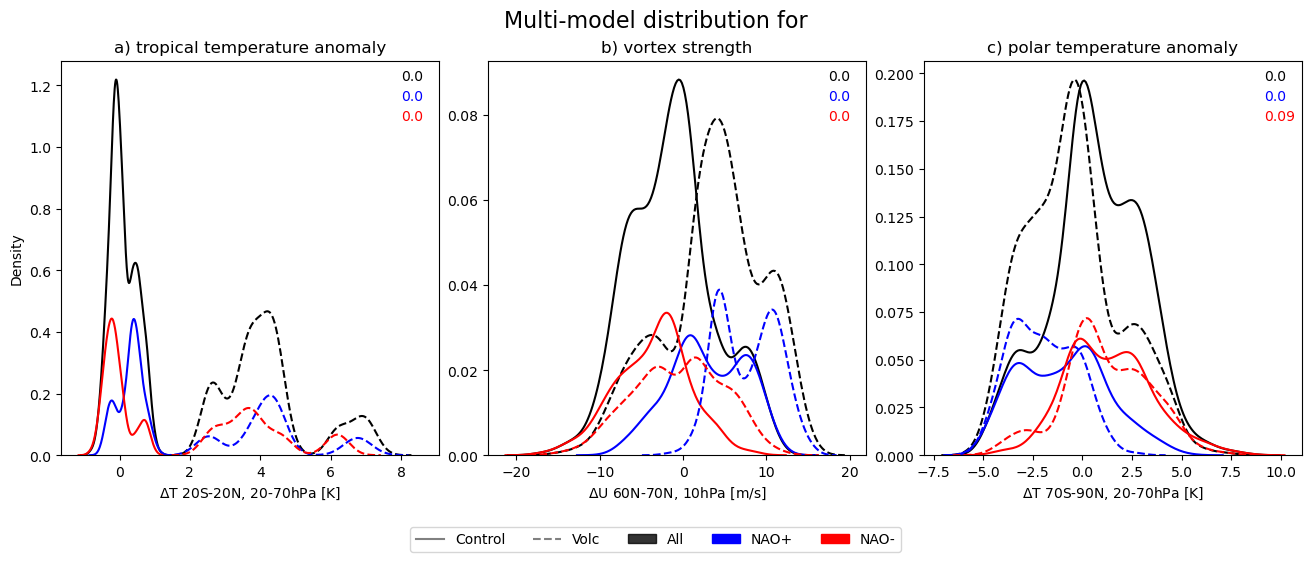

In [7]:
fig, axs = plt.subplots(1,3, figsize=(13,5), layout='constrained')

posnao_pi = results_pi.where(results_pi.flag_nao == 1).dropna()
negnao_pi = results_pi.where(results_pi.flag_nao == -1).dropna()

posnao_volc = results_volc.where(results_volc.flag_nao == 1).dropna()
negnao_volc = results_volc.where(results_volc.flag_nao == -1).dropna()

sns.kdeplot(results_pi, x='deltaT_tropics', color='black', ax=axs[0])
sns.kdeplot(results_volc, x='deltaT_tropics', color='black', ax=axs[0], linestyle='--')
sns.kdeplot(results_pi, x='deltaT_tropics', ax=axs[0], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaT_tropics', ax=axs[0], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(results_pi, x='deltaU', color='black', ax=axs[1])
sns.kdeplot(results_volc, x='deltaU', color='black', ax=axs[1], linestyle='--')
sns.kdeplot(results_pi, x='deltaU', ax=axs[1], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaU', ax=axs[1], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(results_pi, x='deltaT_polar', color='black', ax=axs[2])
sns.kdeplot(results_volc, x='deltaT_polar', color='black', ax=axs[2], linestyle='--')
sns.kdeplot(results_pi, x='deltaT_polar', ax=axs[2], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaT_polar', ax=axs[2], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')

axs[0].text(0.90, 0.95, str(stats.kstest(results_pi.deltaT_tropics.values , results_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='k', transform=axs[0].transAxes, bbox=props)
axs[0].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='b', transform=axs[0].transAxes, bbox=props)
axs[0].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='r',transform=axs[0].transAxes, bbox=props)
axs[1].text(0.90, 0.95, str(stats.kstest(results_pi.deltaU.values , results_volc.deltaU.values, alternative='greater')[1].round(2)), c='k', transform=axs[1].transAxes, bbox=props)
axs[1].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='b', transform=axs[1].transAxes, bbox=props)
axs[1].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='r',transform=axs[1].transAxes, bbox=props)
axs[2].text(0.90, 0.95, str(stats.kstest(results_pi.deltaT_polar.values , results_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='k', transform=axs[2].transAxes, bbox=props)
axs[2].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='b', transform=axs[2].transAxes, bbox=props)
axs[2].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='r',transform=axs[2].transAxes, bbox=props)

axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[1].set_xlabel('$\Delta$U 60N-70N, 10hPa [m/s]')
axs[2].set_xlabel('$\Delta$T 70S-90N, 20-70hPa [K]')
axs[1].set_ylabel('')
axs[2].set_ylabel('')

# axs[0].annotate('a)', xy=(-0.05, 1.05), weight='bold', color='k', xycoords='axes fraction', fontsize=14, ha='left', va='top')
# axs[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')
# axs[2].annotate('c)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)
plt.suptitle('Multi-model distribution for', fontsize=16)
axs[0].set_title('a) tropical temperature anomaly')
axs[1].set_title('b) vortex strength')
axs[2].set_title('c) polar temperature anomaly')
plt.savefig(plotdir + 'figure3.png', dpi=200, bbox_inches='tight')

In [8]:
(results_volc.groupby(['model', 'flag_nao']).mean() - results_pi.groupby(['model', 'flag_nao']).mean()).groupby(['model']).mean()

,deltaT_tropics,deltaT_polar,deltaU
model,,,
CanESM5,4.154663,-1.159448,4.546908
GISS-E2-1-G,3.512626,-0.526317,3.494998
IPSL-CM6A-LR,6.650881,-1.813540,9.490133
MIROC-ES2L,2.701317,-0.214473,2.832876
MPI-ESM1-2-LR,4.385040,-2.810148,8.364000
UKESM1-0-LL,3.220203,-0.291575,1.211115


In [ ]:
mean_all = (results_volc.groupby(['model', 'flag_nao']).mean() - results_pi.groupby(['model', 'flag_nao']).mean()).reset_index()
mean_df = mean_all.where(mean_all.flag_nao != 0).dropna()
df_all = mean_all.groupby('model').mean()
df_all['flag_nao'] = 'all'
df = pd.concat([mean_df, df_all.reset_index()])
df = df.replace({"flag_nao": {-1: 'NAO-', 1: 'NAO+'}})

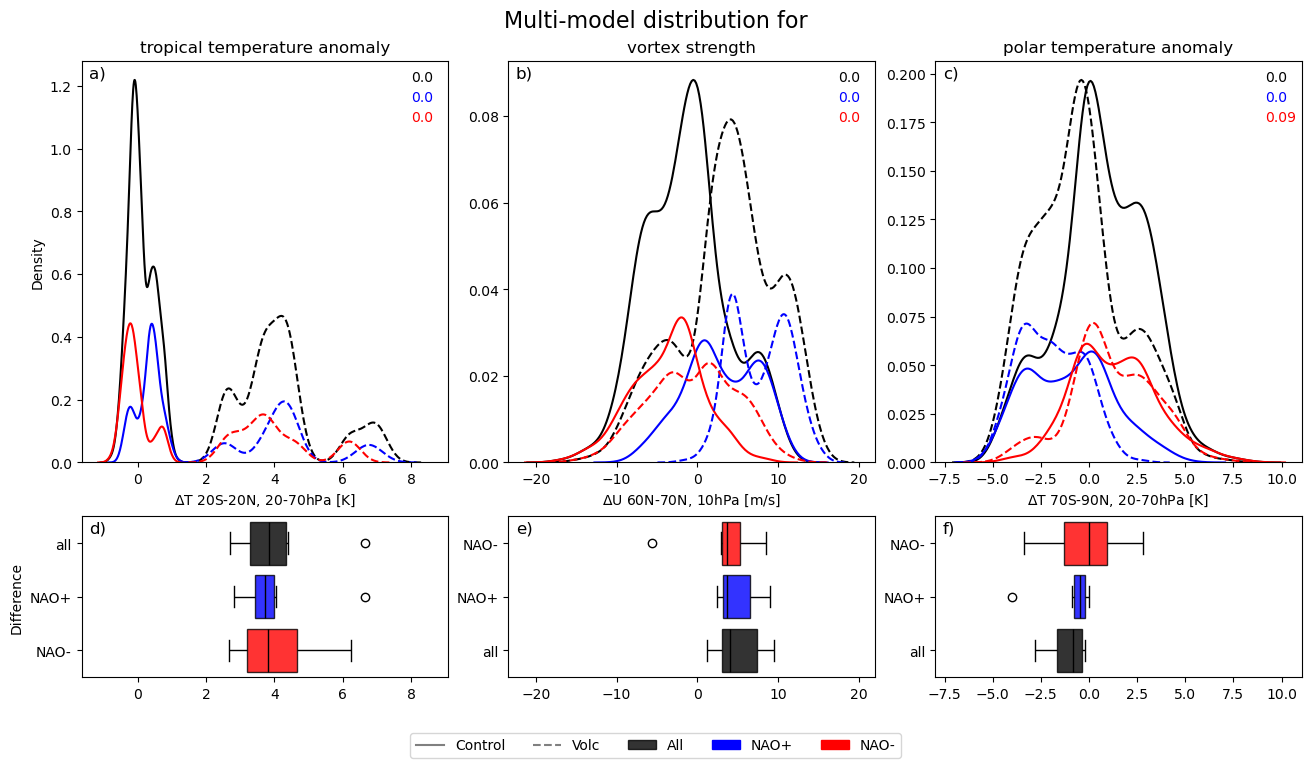

In [11]:
fig, axs = plt.subplots(2,3, figsize=(13,7), layout='constrained', gridspec_kw={'height_ratios': [5,2]})


posnao_pi = results_pi.where(results_pi.flag_nao == 1).dropna()
negnao_pi = results_pi.where(results_pi.flag_nao == -1).dropna()

posnao_volc = results_volc.where(results_volc.flag_nao == 1).dropna()
negnao_volc = results_volc.where(results_volc.flag_nao == -1).dropna()

sns.kdeplot(results_pi, x='deltaT_tropics', color='black', ax=axs[0,0])
sns.kdeplot(results_volc, x='deltaT_tropics', color='black', ax=axs[0,0], linestyle='--')
sns.kdeplot(results_pi, x='deltaT_tropics', ax=axs[0,0], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaT_tropics', ax=axs[0,0], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(results_pi, x='deltaU', color='black', ax=axs[0,1])
sns.kdeplot(results_volc, x='deltaU', color='black', ax=axs[0,1], linestyle='--')
sns.kdeplot(results_pi, x='deltaU', ax=axs[0,1], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaU', ax=axs[0,1], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(results_pi, x='deltaT_polar', color='black', ax=axs[0,2])
sns.kdeplot(results_volc, x='deltaT_polar', color='black', ax=axs[0,2], linestyle='--')
sns.kdeplot(results_pi, x='deltaT_polar', ax=axs[0,2], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(results_volc, x='deltaT_polar', ax=axs[0,2], linestyle='--', hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')

axs[0,0].text(0.90, 0.95, str(stats.kstest(results_pi.deltaT_tropics.values , results_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='k', transform=axs[0,0].transAxes, bbox=props)
axs[0,0].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='b', transform=axs[0,0].transAxes, bbox=props)
axs[0,0].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='r',transform=axs[0,0].transAxes, bbox=props)
axs[0,1].text(0.90, 0.95, str(stats.kstest(results_pi.deltaU.values , results_volc.deltaU.values, alternative='greater')[1].round(2)), c='k', transform=axs[0,1].transAxes, bbox=props)
axs[0,1].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='b', transform=axs[0,1].transAxes, bbox=props)
axs[0,1].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='r',transform=axs[0,1].transAxes, bbox=props)
axs[0,2].text(0.90, 0.95, str(stats.kstest(results_pi.deltaT_polar.values , results_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='k', transform=axs[0,2].transAxes, bbox=props)
axs[0,2].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='b', transform=axs[0,2].transAxes, bbox=props)
axs[0,2].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='r',transform=axs[0,2].transAxes, bbox=props)

axs[0,0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[0,1].set_xlabel('$\Delta$U 60N-70N, 10hPa [m/s]')
axs[0,2].set_xlabel('$\Delta$T 70S-90N, 20-70hPa [K]')
axs[0,1].set_ylabel('')
axs[0,2].set_ylabel('')

axs[0,0].annotate('a)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)
axs[0,1].annotate('b)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)
axs[0,2].annotate('c)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)
plt.suptitle('Multi-model distribution for', fontsize=16)
axs[0,0].set_title('tropical temperature anomaly')
axs[0,1].set_title('vortex strength')
axs[0,2].set_title('polar temperature anomaly')

sns.boxplot(data=df, ax=axs[1,0], x='deltaT_tropics', y='flag_nao', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8))
sns.boxplot(data=df, ax=axs[1,1], x='deltaU', y='flag_nao', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8))
sns.boxplot(data=df, ax=axs[1,2], x='deltaT_polar', y='flag_nao', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8))
axs[1,0].invert_yaxis()
axs[1,0].set_ylabel('Difference')
axs[1,1].set_ylabel('')
axs[1,2].set_ylabel('')
axs[1,0].set_xlim(axs[0,0].get_xlim())
axs[1,1].set_xlim(axs[0,1].get_xlim())
axs[1,2].set_xlim(axs[0,2].get_xlim())
axs[1,0].set_xlabel('')
axs[1,1].set_xlabel('')
axs[1,2].set_xlabel('')

axs[1,0].annotate('d)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)
axs[1,1].annotate('e)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)
axs[1,2].annotate('f)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)

plt.savefig(plotdir + 'figure3_quant.png', dpi=200, bbox_inches='tight')

In [56]:
nao_flags


year    nao_pi  flag_pi  nao_volc  flag_volc
model       realization                                                    
CanESM5     r1i1p2f1     5552-02-01 -0.001352        0  0.619078          1
            r2i1p2f1     5557-02-01  0.125872        0 -1.742433         -1
            r3i1p2f1     5575-02-01  1.143758        1  0.715891          1
            r4i1p2f1     5622-02-01  0.211339        0  0.104238          0
            r5i1p2f1     5643-02-01 -0.593414       -1 -1.025887         -1
...                             ...       ...      ...       ...        ...
UKESM1-0-LL r21i1p1f2    3123-02-01  2.542346        1  1.365885          1
            r22i1p1f2    3074-02-01  1.863322        1 -0.023668          0
            r23i1p1f2    3104-02-01  1.020190        1  1.619856          1
            r24i1p1f2    3077-02-01  0.504877        1 -1.474555         -1
            r25i1p1f2    3181-02-01  1.424958        1  0.389597          0

[261 rows x 5 columns]

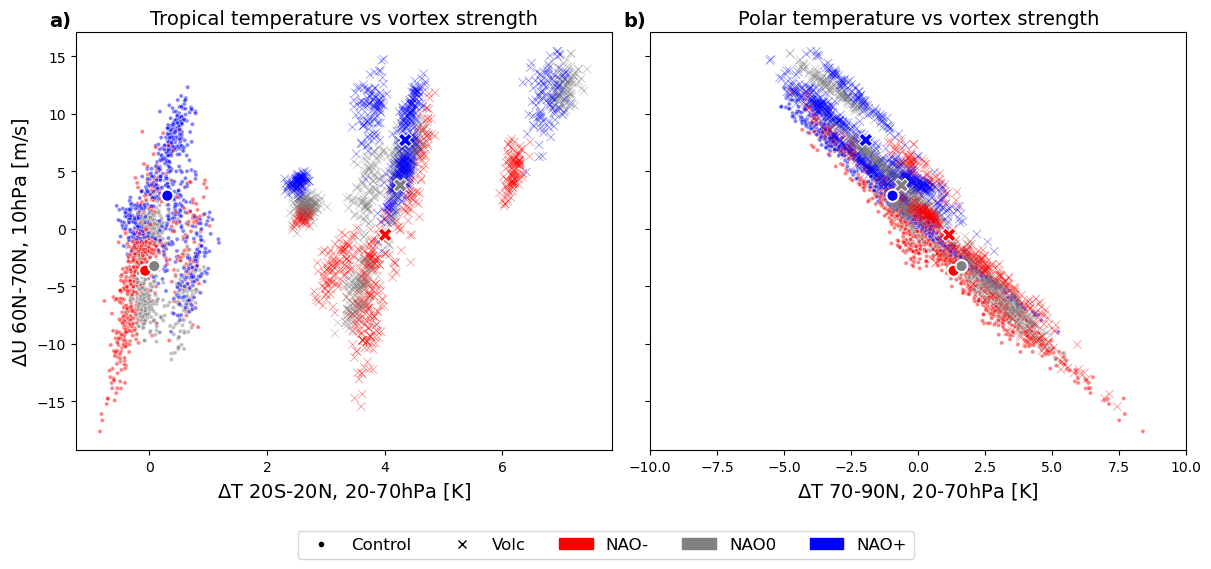

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(12,5), sharey=True, layout='constrained')
colors = ['red', 'grey', 'blue']

# for i, model in enumerate(models):
c = sns.scatterplot(results_pi.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_nao', palette=colors, marker='.', alpha=0.5, ax=axs[0], legend=False)
c = sns.scatterplot(results_pi.drop('model', axis=1).groupby('flag_nao').mean(), x='deltaT_tropics', y='deltaU', hue='flag_nao', palette=colors, marker='.', s=300, ax=axs[0], legend=False)
e = sns.scatterplot(results_volc.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_nao', palette=colors, marker='x', alpha=0.5, ax=axs[0], legend=False)
e = sns.scatterplot(results_volc.drop('model', axis=1).groupby('flag_nao').mean(), x='deltaT_tropics', y='deltaU', hue='flag_nao', palette=colors, marker='X', s=100, ax=axs[0], legend=False)

sns.scatterplot(results_pi.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_nao', palette=colors, marker='.', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(results_volc.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_nao', palette=colors, marker='x', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(results_pi.groupby('flag_nao').mean(), x='deltaT_polar', y='deltaU', hue='flag_nao', palette=colors, marker='.', s=300, ax=axs[1], legend=False)
sns.scatterplot(results_volc.groupby('flag_nao').mean(), x='deltaT_polar', y='deltaU', hue='flag_nao', palette=colors, marker='X', s=100, ax=axs[1], legend=False)

axs[1].set_xlim(-10,10)

axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]', fontsize=14)
axs[1].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]', fontsize=14)
axs[0].set_ylabel('$\Delta$U 60N-70N, 10hPa [m/s]', fontsize=14)

axs[0].set_title('Tropical temperature vs vortex strength', fontsize=14)
axs[1].set_title('Polar temperature vs vortex strength', fontsize=14)

axs[0].annotate('a)', xy=(-0.05, 1.05), weight='bold', color='k', xycoords='axes fraction', fontsize=14, ha='left', va='top')
axs[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')
# legend
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

piControl = Line2D([0], [0], label='Control', color='black', marker='.', linestyle='None')
volc = Line2D([0], [0], label='Volc', color='black', linestyle='None', marker='x')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
blue_patch = mpatches.Patch(color='blue', label='NAO+')
grey_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')
fig.legend(handles=[piControl, volc, red_patch, grey_patch, blue_patch], loc='center', ncol=5, fontsize=12, bbox_to_anchor=(0.5,-0.08))

plt.savefig(plotdir + 'figure2.png', dpi=200, bbox_inches='tight')

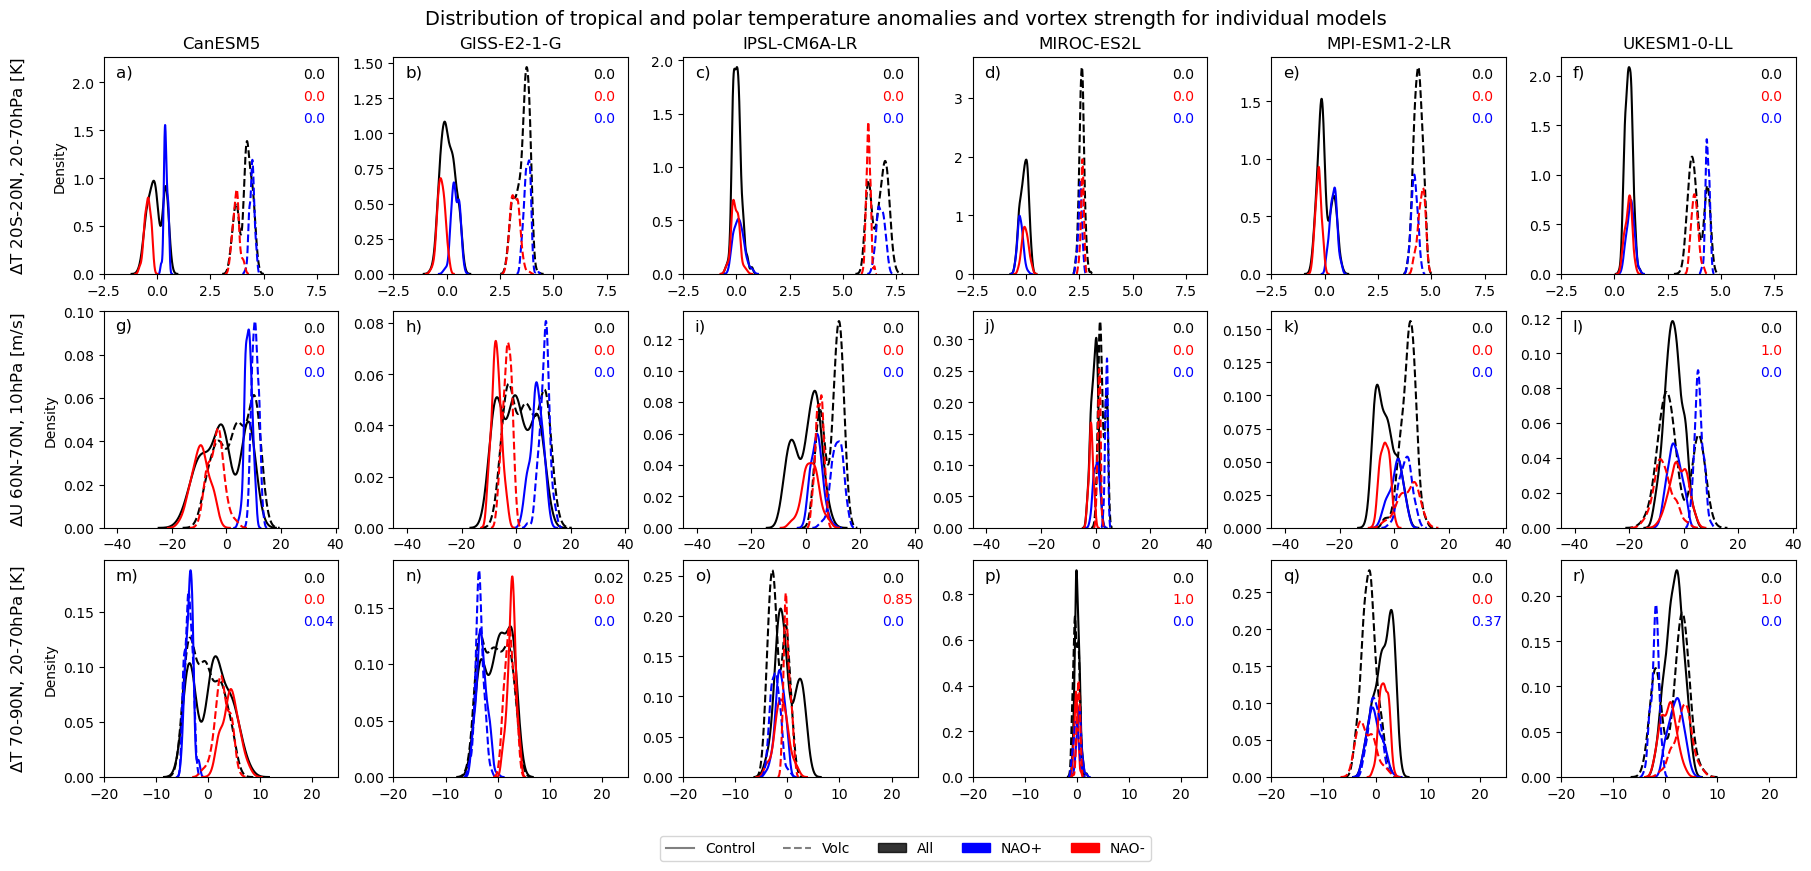

In [45]:
fig, axs = plt.subplots(3,6, figsize=(18,8), layout='constrained')

alist = ['a)', 'b)', 'c)', 'd)', 'e)','f)']
blist = [ 'g)', 'h)', 'i)', 'j)','k)', 'l)']
clist = [ 'm)', 'n)', 'o)', 'p)','q)', 'r)']

for i, model in enumerate(models):
    all_pi = results_pi.loc[model]
    all_volc = results_volc.loc[model]

    sns.kdeplot(all_pi, x='deltaT_tropics', color='k', ax=axs[0, i])
    sns.kdeplot(all_volc, x='deltaT_tropics', c='k', linestyle='--', ax=axs[0, i], legend=False)
    sns.kdeplot(all_pi, x='deltaT_tropics', ax=axs[0, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaT_tropics', linestyle='--', ax=axs[0, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    sns.kdeplot(all_pi, x='deltaU', color='k', ax=axs[1, i])
    sns.kdeplot(all_volc, x='deltaU', c='k', linestyle='--', ax=axs[1, i], legend=False)
    sns.kdeplot(all_pi, x='deltaU', ax=axs[1, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaU', linestyle='--', ax=axs[1, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    sns.kdeplot(all_pi, x='deltaT_polar', color='k', ax=axs[2, i])
    sns.kdeplot(all_volc, x='deltaT_polar', c='k', linestyle='--', ax=axs[2, i], legend=False)
    sns.kdeplot(all_pi, x='deltaT_polar', ax=axs[2, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaT_polar', linestyle='--', ax=axs[2, i], hue='flag_nao', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    axs[0,i].annotate(alist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
    axs[1,i].annotate(blist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
    axs[2,i].annotate(clist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)

    props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')
    posnao_pi = results_pi.where(results_pi.flag_nao == 1).dropna().loc[model]
    negnao_pi = results_pi.where(results_pi.flag_nao == -1).dropna().loc[model]
    posnao_volc = results_volc.where(results_volc.flag_nao == 1).dropna().loc[model]
    negnao_volc = results_volc.where(results_volc.flag_nao == -1).dropna().loc[model]

    axs[0,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaT_tropics.values , all_volc.deltaT_tropics.values, alternative='greater')[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='k')
    axs[0,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, alternative='greater')[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='r')
    axs[0,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, alternative='greater')[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='b')
    axs[2,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaT_polar.values , all_volc.deltaT_polar.values, alternative='less')[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='k')
    axs[2,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='r')
    axs[2,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='b')
    axs[1,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaU.values , all_volc.deltaU.values, alternative='greater')[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='k')
    axs[1,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values, alternative='greater')[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='r')
    axs[1,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values, alternative='greater')[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='b')

    axs[0,i].set_title(model)
    axs[0,i].set_xlim(-2.5,8.5)
    axs[1,i].set_xlim(-45,41)
    axs[2,i].set_xlim(-20,25)
    axs[0,i].set_ylabel('')
    axs[1,i].set_ylabel('')
    axs[2,i].set_ylabel('')
    axs[0,i].set_xlabel('')
    axs[1,i].set_xlabel('')
    axs[2,i].set_xlabel('')

axs[0,0].set_ylabel('Density')   
axs[1,0].set_ylabel('Density')   
axs[2,0].set_ylabel('Density')   

axs[0,0].annotate('$\Delta$T 20S-20N, 20-70hPa [K]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)
axs[1,0].annotate('$\Delta$U 60N-70N, 10hPa [m/s]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)
axs[2,0].annotate('$\Delta$T 70-90N, 20-70hPa [K]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)

plt.suptitle('Distribution of tropical and polar temperature anomalies and vortex strength for individual models', fontsize=14)

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)

plt.savefig(plotdir + 'supp5.png', dpi=200, bbox_inches='tight')